# Unmix a hyperspectral image

A pixel may contain several materials. This notebook estimates their spectra and
fractions, then asks whether a small reconstruction error also means good recovery.
It uses analytic synthetic spectra with **exact** reference fractions: no data
account, GPU or download is needed. These spectra are not laboratory measurements.

From the repository root, install `python -m pip install -e ".[dev]" -c constraints.txt`
and select that environment as your notebook kernel. All code is ordinary Python;
`python scripts/execute_notebook.py` also checks the cells without a Jupyter server.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from threadpoolctl import threadpool_limits

from spectral_unmixing.algorithms import unmix
from spectral_unmixing.data import false_color, synthetic_scene
from spectral_unmixing.metrics import evaluate

scene = synthetic_scene(size=48, bands=96, seed=0, snr_db=35, regime="pure")
print("Observed cube:", scene.cube.shape)
print("Exact abundance maps:", scene.abundances.shape)
print("Synthetic metadata:", scene.metadata)

Observed cube: (48, 48, 96)
Exact abundance maps: (48, 48, 3)
Synthetic metadata: {'synthetic': True, 'seed': 0, 'regime': 'pure', 'requested_snr_db': 35, 'actual_snr_db': 35.0, 'clipped_values': 0, 'spectral_axis': 'synthetic band index', 'reference_status': 'exact analytic linear-mixture ground truth'}


## The linear mixture

Write `X ≈ A @ E`: X has one row per pixel, E one row per component spectrum,
and A one row of fractions per pixel. A is nonnegative and each row sums to one.
This example has pure patches and 35 dB noise. The false-color preview stretches
three display channels only; the fitting code receives the original cube.

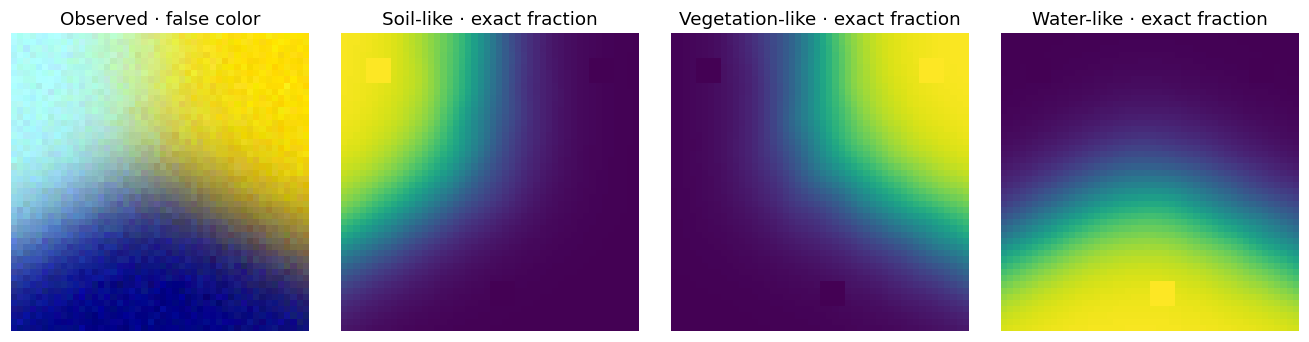

In [2]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3), layout="constrained")
axes[0].imshow(false_color(scene.cube))
axes[0].set_title("Observed · false color")
for j, material in enumerate(scene.materials):
    axes[j + 1].imshow(scene.abundances[..., j], vmin=0, vmax=1, cmap="viridis")
    axes[j + 1].set_title(material + " · exact fraction")
for ax in axes:
    ax.set_axis_off()
plt.show()

## Fit without reference labels

SPA selects candidate pure pixels; FCLS solves their constrained fractions.
Simplex NMF then updates spectra and fractions jointly. Spatial NMF adds a
four-neighbor smoothness penalty. Every method receives only the observed cube,
K=3 and fixed settings. The 300-step NMF budget is the same as the main experiment.

In [3]:
methods = ["spa-fcls", "simplex-nmf", "spatial-nmf"]
fits, aligned, scores = {}, {}, {}
with threadpool_limits(limits=1):
    for method in methods:
        fitted = unmix(scene.cube, 3, method=method, seed=0)
        metrics, endmembers, abundances = evaluate(scene, fitted)
        fits[method] = fitted
        aligned[method] = (endmembers, abundances.reshape(48, 48, 3))
        scores[method] = metrics
        print(f"{method:12s}  SAD={metrics['mean_endmember_sad_deg']:.3f} deg  "
              f"fraction RMSE={metrics['abundance_rmse']:.4f}  "
              f"relative residual={metrics['relative_reconstruction_error']:.5f}")

spa-fcls      SAD=1.172 deg  fraction RMSE=0.0061  relative residual=0.02286
simplex-nmf   SAD=0.306 deg  fraction RMSE=0.0069  relative residual=0.01758
spatial-nmf   SAD=1.442 deg  fraction RMSE=0.0281  relative residual=0.01760


## Compare fractions on one scale

Component order is arbitrary in blind unmixing. **After fitting**, Hungarian
matching aligns estimated spectra to reference spectra by angle; the same
permutation is applied to fractions. This matching does not modify the fitted
values. Every map below uses the same [0, 1] scale. Spatially smoother maps do not
necessarily give more accurate fractions.

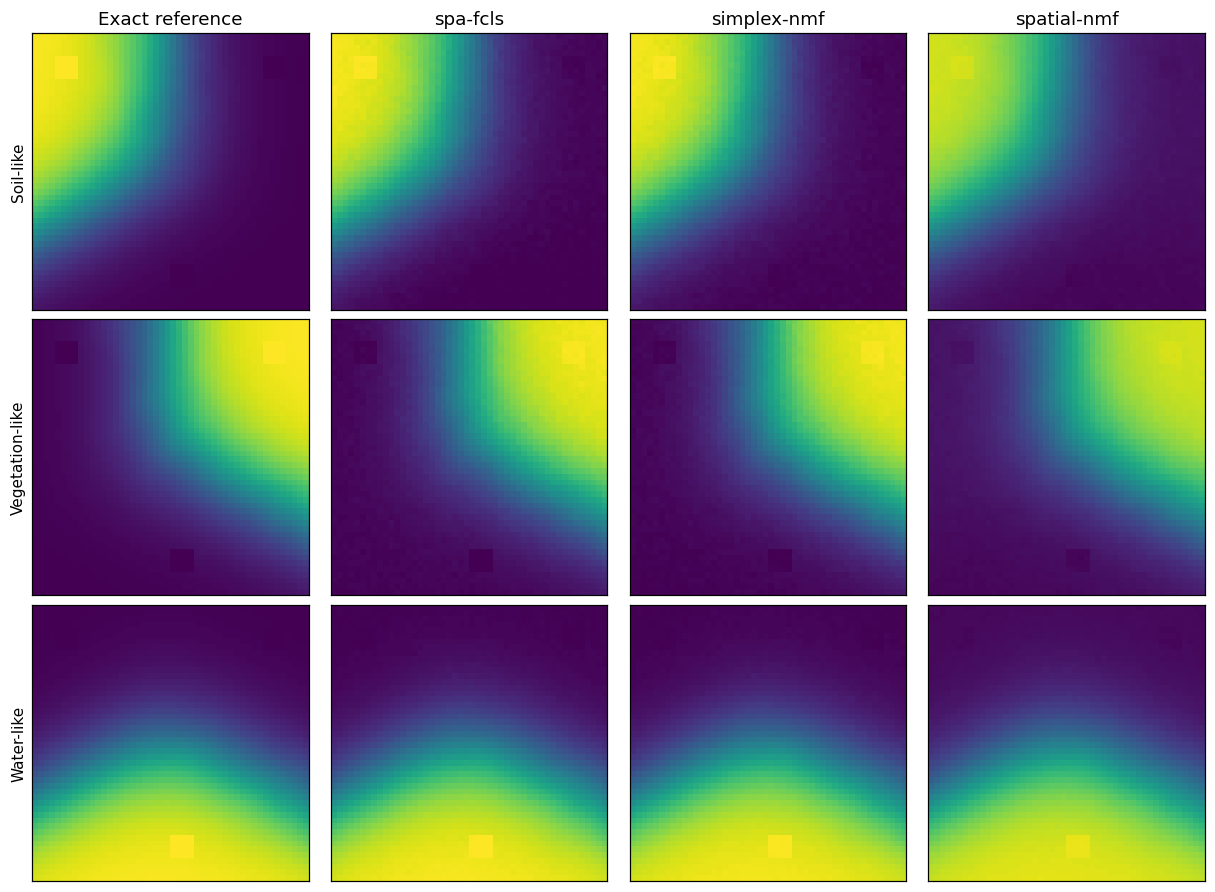

In [4]:
fig, axes = plt.subplots(3, 4, figsize=(11, 8), layout="constrained")
for j, material in enumerate(scene.materials):
    maps = [scene.abundances[..., j]] + [aligned[m][1][..., j] for m in methods]
    for column, image in enumerate(maps):
        axes[j, column].imshow(image, vmin=0, vmax=1, cmap="viridis")
        axes[j, column].set_xticks([])
        axes[j, column].set_yticks([])
    axes[j, 0].set_ylabel(material)
for ax, title in zip(axes[0], ["Exact reference"] + methods):
    ax.set_title(title)
plt.show()

## Inspect one pixel

Each contribution is a fraction multiplied by its component spectrum. Their sum
is the reconstructed spectrum. A visually close reconstruction is useful, but
several different decompositions may explain the same observation. The real
Samson and Jasper Ridge experiments make this limitation especially clear.

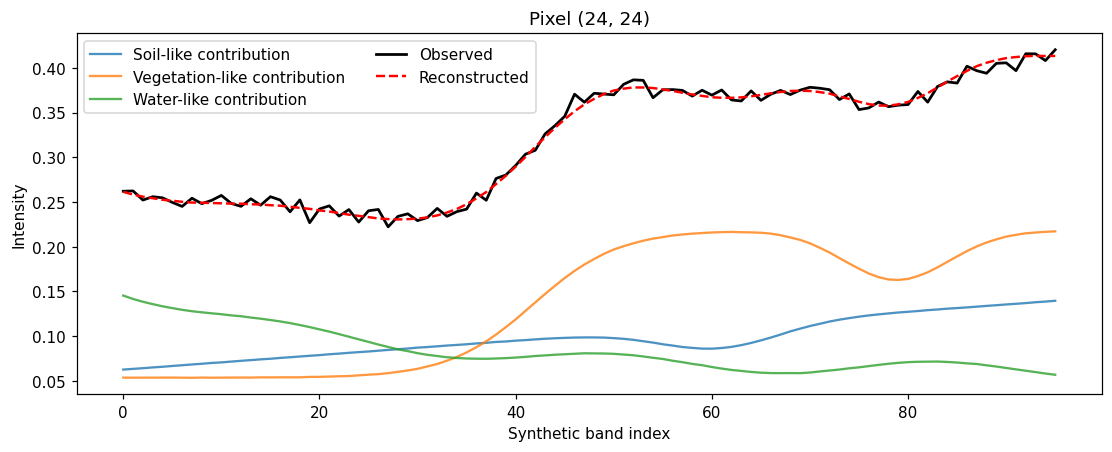

Estimated fractions: [0.2077 0.339  0.4533]
Exact fractions:     [0.2108 0.3382 0.451 ]
Maximum sum-to-one error: 2.220446049250313e-16


In [5]:
row, column = 24, 24
e, a = aligned["simplex-nmf"]
fractions = a[row, column]
contributions = fractions[:, None] * e
observed = scene.cube[row, column]
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
for material, contribution in zip(scene.materials, contributions):
    ax.plot(contribution, label=material + " contribution", alpha=0.8)
ax.plot(observed, color="black", lw=1.8, label="Observed")
ax.plot(contributions.sum(axis=0), "r--", lw=1.6, label="Reconstructed")
ax.set(xlabel="Synthetic band index", ylabel="Intensity", title=f"Pixel ({row}, {column})")
ax.legend(ncol=2)
plt.show()
print("Estimated fractions:", np.round(fractions, 4))
print("Exact fractions:    ", np.round(scene.abundances[row, column], 4))
print("Maximum sum-to-one error:", np.max(abs(a.sum(axis=-1) - 1)))

## Change the assumptions

- Set `regime="mixed"` to remove pure pixels: all true fractions lie in [0.1, 0.8].
- Set `snr_db=20` for stronger noise, or `snr_db=None` for a noise-free observation.
- Inspect the errors as well as the residual. A low residual alone cannot identify
  a unique physical mixture.

The [full experiment report](../docs/experiment.md) retains all 112 fits and five
seeds rather than selecting a favorable restart. Read the
[methodology](../docs/methodology.md) for objectives and stopping criteria, and the
[references](../docs/references.md) for data and algorithm sources.